# 05 - Event–Ridership Merge Walkthrough

Walks through the merged training dataset built by `src.dataset.build_dataset`: how many Events get a trusted Event End and a real Attendance, which Events are dropped and why, the exit curve per event type, and whether the Baseline tracks demand on quiet nights.

All logic lives in `src/`; this notebook only calls it. Terms follow `CONTEXT.md`; settled decisions are in `DECISIONS.md`.

In [1]:
import sys
from pathlib import Path

# Resolve project root dynamically regardless of notebook working directory
PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == 'notebooks':
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import logging
import pandas as pd
import matplotlib.pyplot as plt

from src.baseline import add_baseline, affected_slots, drop_events_without_baseline
from src.dataset import assign_split, build_dataset
from src.events import load_events
from src.features import consolidate_demand_matrices
from src.weather import load_weather

logging.basicConfig(level=logging.ERROR)  # drops are reported below, not as log noise
pd.set_option('display.width', 140)

def plot_exit_curves(curves, counts, title, ylabel):
    """One line per column of a Minutes Since End × group table."""
    fig, ax = plt.subplots(figsize=(10, 5))
    for col in curves.columns:
        ax.plot(curves.index, curves[col], marker='o', label=f'{col} (n={counts[col]})')
    ax.axvline(0, color='grey', ls='--', lw=1)
    ax.axhline(0, color='black', lw=0.8)
    ax.set(xlabel='Minutes Since End', ylabel=ylabel, title=title, xticks=curves.index)
    ax.legend()
    plt.show()

### 1. Load the Event table, demand grid and dataset
`build_dataset` is the same call `python -m src.dataset` makes, so the rows here match `data/processed/event_dataset.parquet`.

In [2]:
events = load_events()
demand = consolidate_demand_matrices()
rows = build_dataset(events, demand, load_weather())
grid = add_baseline(demand, events)  # demand + Baseline + Surge Delta on every bucket, for sections 3 and 5
print(f'Events: {len(events):,} | demand buckets: {len(demand):,} | dataset rows: {len(rows):,}')
rows.groupby('split').agg(events=('event_id', 'nunique'), rows=('event_id', 'size')).loc[['train', 'val', 'test']]

Events: 353 | demand buckets: 140,352 | dataset rows: 2,480


,events,rows
split,,
train,99,792
val,49,392
test,162,1296


In [3]:
# Every Event contributes the full 8-bucket Prediction Window, −30 … +75 Minutes Since End
per_event = rows.groupby('event_id').minutes_since_end.agg(list)
assert per_event.map(lambda m: m == list(range(-30, 90, 15))).all()
assert rows.surge_delta.notna().all() and rows.baseline.notna().all()
print('Every Event has 8 rows on the fixed grid and a full Baseline.')

Every Event has 8 rows on the fixed grid and a full Baseline.


### 2. Coverage: End Time Basis and Attendance Basis
Counts over held Events (the only ones that become rows), all held vs. those kept in the dataset.

In [4]:
events.event_status.value_counts()

event_status
held         345
cancelled      6
duplicate      1
postponed      1
Name: count, dtype: int64

In [5]:
held = events[events.event_status == 'held']
kept = held[held.event_id.isin(rows.event_id)]

def basis_counts(column):
    return pd.DataFrame({'held': held[column].replace('', '(blank)').value_counts(),
                         'in dataset': kept[column].replace('', '(blank)').value_counts()}).fillna(0).astype(int)

basis_counts('end_time_basis')

,held,in dataset
end_time_basis,,
calibrated_category,159,154
box_score,149,135
published_runtime,31,15
broadcast_window,6,6


In [6]:
basis_counts('attendance_basis')

,held,in dataset
attendance_basis,,
box_score,149,135
(blank),145,126
tour_boxscore,46,44
reported,5,5


In [7]:
# Attendance coverage per event type, kept Events only (blank = no real figure, never capacity)
(kept.assign(has_attendance=kept.attendance.notna())
     .groupby('event_type').has_attendance.agg(events='size', with_attendance='sum')
     .sort_values('events', ascending=False))

,events,with_attendance
event_type,,
basketball,141,135
concert,124,44
family_show,15,0
comedy,8,0
food_drink_event,4,0
community_event,3,0
boxing,3,2
wrestling,3,3
bull_riding,2,0


### 3. Dropped Events
A held Event is dropped when its Prediction Window lacks a Baseline (a missing Event End counts as lacking one) or its Event Start falls outside every split (Jan–Feb 2024). The assert catches any new drop rule added to `build_dataset`. Dropped Events still shape Affected Slots and Next Showing Gap for others.

In [8]:
# Reasons overlap: most Jan–Feb 2024 Events also lack a Baseline (no Dec 2023 data)
dropped = held[~held.event_id.isin(rows.event_id)].copy()
dropped['no_baseline'] = ~dropped.index.isin(drop_events_without_baseline(dropped, grid).index)
dropped['outside_split'] = assign_split(dropped.event_start).isna()
assert (dropped.no_baseline | dropped.outside_split).all(), 'an Event was dropped for an unlisted reason'
print(f'{len(dropped)} of {len(held)} held Events dropped')
pd.crosstab(dropped.no_baseline, dropped.outside_split, margins=True)

35 of 345 held Events dropped


outside_split,False,True,All
no_baseline,,,
False,0,18,18
True,2,15,17
All,2,33,35


In [9]:
dropped.sort_values('event_start')[['event_id', 'event_name', 'event_type', 'event_end', 'no_baseline', 'outside_split']]

,event_id,event_name,event_type,event_end,no_baseline,outside_split
0,BARCLAYS_20240105_1930,Brooklyn Nets vs. Oklahoma City Thunder,basketball,2024-01-05 22:03:17,True,True
1,BARCLAYS_20240107_1500,Brooklyn Nets vs. Portland Trailblazers,basketball,2024-01-07 17:51:11,True,True
2,BARCLAYS_20240115_1930,Brooklyn Nets vs. Miami Heat,basketball,2024-01-15 22:11:39,True,True
3,BARCLAYS_20240118_1900,Disney On Ice,family_show,2024-01-18 20:45:00,True,True
4,BARCLAYS_20240119_1100,Disney On Ice,family_show,2024-01-19 12:45:00,True,True
5,BARCLAYS_20240119_1900,Disney On Ice,family_show,2024-01-19 20:45:00,True,True
6,BARCLAYS_20240120_1100,Disney On Ice,family_show,2024-01-20 12:45:00,True,True
7,BARCLAYS_20240120_1500,Disney On Ice,family_show,2024-01-20 16:45:00,True,True
8,BARCLAYS_20240120_1900,Disney On Ice,family_show,2024-01-20 20:45:00,True,True
9,BARCLAYS_20240121_1200,Disney On Ice,family_show,2024-01-21 13:45:00,True,True


### 4. Exit curves by event type
Mean Surge Delta per Minutes Since End, for event types with at least 5 Events in the dataset. Offset 0 is the bucket holding Event End.

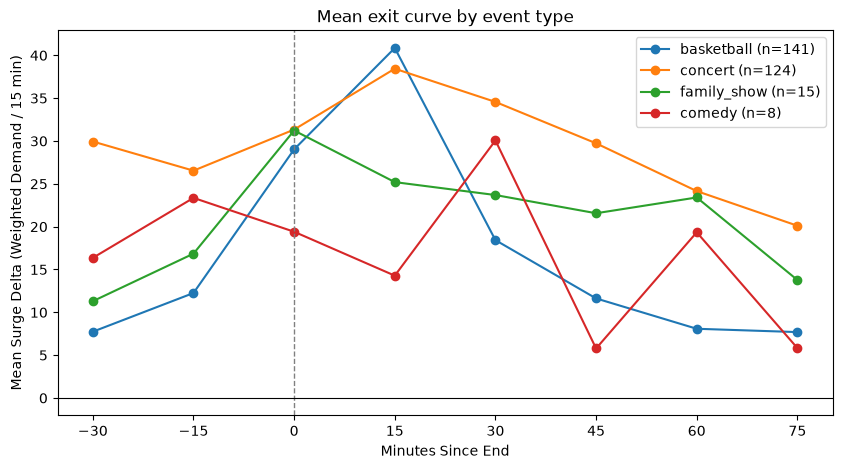

event_type,basketball,concert,family_show,comedy
minutes_since_end,,,,
-30,7.7,29.9,11.3,16.4
-15,12.3,26.5,16.8,23.4
0,29.0,31.3,31.2,19.4
15,40.9,38.4,25.2,14.3
30,18.4,34.6,23.7,30.1
45,11.6,29.7,21.6,5.8
60,8.1,24.2,23.4,19.3
75,7.7,20.1,13.8,5.8


In [10]:
counts = rows.groupby('event_type').event_id.nunique()
types = counts[counts >= 5].sort_values(ascending=False).index
curves = rows[rows.event_type.isin(types)].pivot_table(index='minutes_since_end', columns='event_type',
                                                      values='surge_delta', aggfunc='mean')[types]
plot_exit_curves(curves, counts, 'Mean exit curve by event type', 'Mean Surge Delta (Weighted Demand / 15 min)')
curves.round(1)

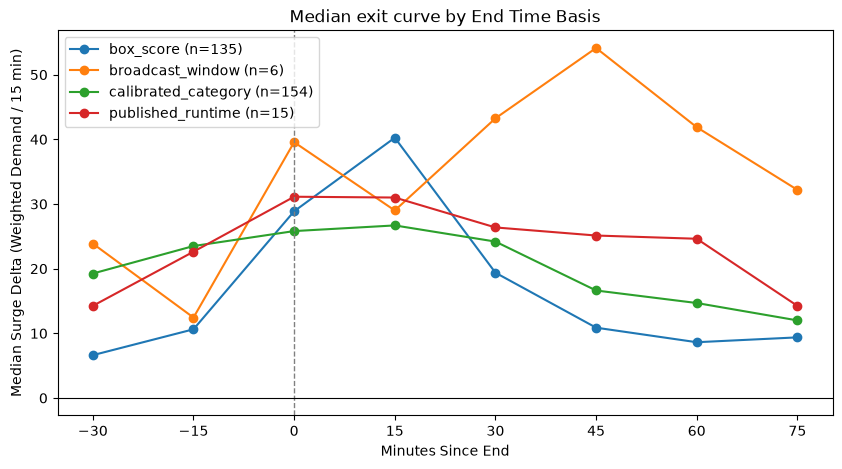

end_time_basis,box_score,broadcast_window,calibrated_category,published_runtime
minutes_since_end,,,,
-30,6.6,23.9,19.2,14.2
-15,10.6,12.4,23.5,22.6
0,28.9,39.6,25.8,31.1
15,40.2,29.0,26.7,31.0
30,19.4,43.2,24.2,26.4
45,10.9,54.1,16.6,25.1
60,8.6,41.9,14.7,24.6
75,9.4,32.2,12.0,14.2


In [11]:
# Median exit curve by End Time Basis (median: 6 broadcast_window Events are too few for a stable mean).
# A sharper peak near 0 means a more trustworthy Event End.
by_basis = rows.pivot_table(index='minutes_since_end', columns='end_time_basis', values='surge_delta', aggfunc='median')
n_basis = rows.groupby('end_time_basis').event_id.nunique()
plot_exit_curves(by_basis, n_basis, 'Median exit curve by End Time Basis', 'Median Surge Delta (Weighted Demand / 15 min)')
by_basis.round(1)

### 5. Baseline vs demand sanity checks
All Events in the table are at Barclays, so Citi Field has no Affected Slots and serves as a pure control. On slots no Event touches, Weighted Demand should scatter around the Baseline (Surge Delta ≈ 0). Inside Prediction Windows it should sit well above.

In [12]:
grid['affected_slot'] = affected_slots(grid, events)
grid = grid[grid.baseline.notna()]


(grid.groupby(['venue', 'affected_slot']).surge_delta
     .describe(percentiles=[0.25, 0.5, 0.75])[['count', 'mean', '25%', '50%', '75%']].round(2))

count  mean   25%   50%    75%
venue      affected_slot                                  
barclays   False          58069.0  0.77 -6.00  0.25   7.00
           True            9357.0  9.82 -5.88  6.38  22.38
citi_field False          67968.0  1.14 -4.12  0.00   4.62

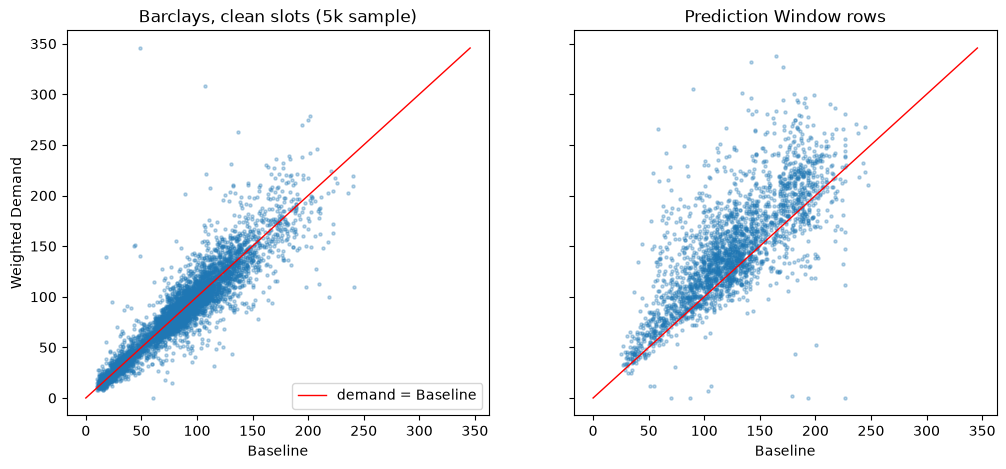

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)
quiet = grid[(grid.venue == 'barclays') & ~grid.affected_slot].sample(5000, random_state=0)
top = max(quiet.baseline.max(), quiet.weighted_demand.max(), rows.baseline.max(), rows.weighted_demand.max())
for ax, data, title in [(axes[0], quiet, 'Barclays, clean slots (5k sample)'),
                        (axes[1], rows, 'Prediction Window rows')]:
    ax.scatter(data.baseline, data.weighted_demand, s=5, alpha=0.3)
    ax.plot([0, top], [0, top], color='red', lw=1, label='demand = Baseline')
    ax.set(xlabel='Baseline', title=title)
axes[0].set_ylabel('Weighted Demand')
axes[0].legend()
plt.show()

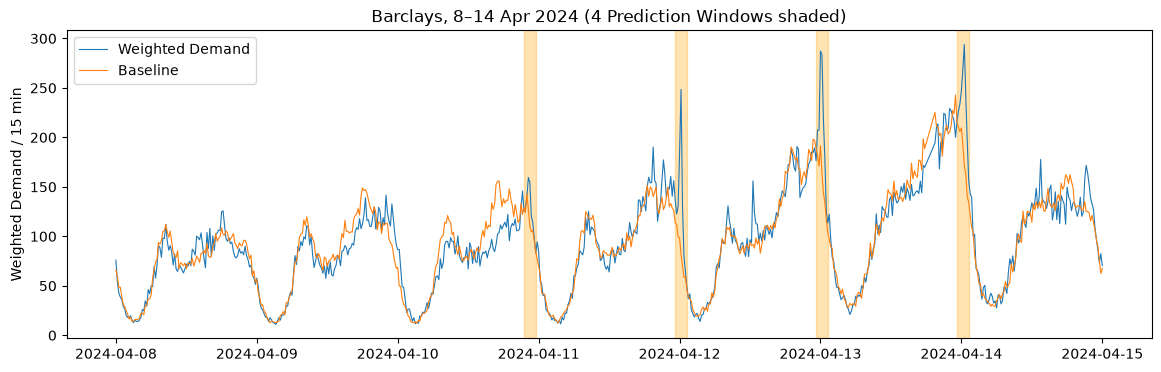

In [14]:
# One busy Barclays week: demand vs Baseline, Prediction Windows shaded
start, end = '2024-04-08', '2024-04-15'
week = grid[(grid.venue == 'barclays') & grid.timestamp_15m.between(start, end)]
windows = rows[(rows.venue == 'barclays') & rows.event_start.between(start, end)].groupby('event_id').time_bin

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(week.timestamp_15m, week.weighted_demand, lw=0.8, label='Weighted Demand')
ax.plot(week.timestamp_15m, week.baseline, lw=0.8, label='Baseline')
for w in windows.agg(['min', 'max']).itertuples():
    ax.axvspan(w.min, w.max + pd.Timedelta('15min'), color='orange', alpha=0.3)
ax.set(ylabel='Weighted Demand / 15 min', title=f'Barclays, 8–14 Apr 2024 ({windows.ngroups} Prediction Windows shaded)')
ax.legend()
plt.show()

### 6. Open points carried from #10
- **`is_weekend` counts Friday** (`[4, 5, 6]` in `src/features.py`). The table below shows Surge Delta by weekday to inform the call.
- **Short lags leak within the window**: `demand_lag_1/2/4` and `rolling_*` at +15 … +75 include demand from inside the same Prediction Window, so those rows only support one-bucket-ahead prediction. Not measured here; deferred to the modelling work and noted for #12.

In [15]:
rows.groupby('day_of_week').agg(events=('event_id', 'nunique'), mean_surge=('surge_delta', 'mean'),
                                median_surge=('surge_delta', 'median'), is_weekend=('is_weekend', 'first')).round(1)

,events,mean_surge,median_surge,is_weekend
day_of_week,,,,
0,43,24.4,16.1,0
1,51,24.5,17.1,0
2,48,25.6,20.4,0
3,64,22.8,17.5,0
4,64,21.1,15.4,1
5,88,20.1,19.1,1
6,88,20.2,16.7,1


### Findings (run of 2026-11-06)
- **Coverage**: 310 of 345 held Events become rows (2,480 rows; train 99, val 49, test 162 Events). Event End is `calibrated_category` for 154 of them, `box_score` 135, `published_runtime` 15, `broadcast_window` 6. Attendance is blank for 126 (mostly concerts and every family show).
- **Drops**: 35 held Events. 18 only for starting in Jan–Feb 2024 (outside every split), 15 for that and a missing Baseline, 2 (Iron Maiden, Kacey Musgraves, Nov 2024) for a missing Baseline alone.
- **Exit curves**: basketball peaks sharply at +15 min; concerts are flatter and stay elevated through +75. Box-score ends give the sharpest peak; calibrated ends smear it, as expected from a per-category median.
- **Baseline sanity**: on clean slots median Surge Delta is ~0 at both venues (0.25 Barclays, 0.00 Citi Field; means +0.8, +1.1). Barclays Prediction Window rows sit clearly above the Baseline.
- **Weekend flag**: Friday's mean Surge Delta (21.1) sits between weekdays (22.8–25.6) and weekends (20.1–20.2); the data doesn't settle whether Friday belongs in `is_weekend`.